# Figure 3 — RNA–ligand binding-site prediction

Four panels, drawn from `raw_data/`, the Source Data submitted with the paper:

| panel | what it draws | source table |
|---|---|---|
| **3a** | F1/MCC at Youden's J, F1/MCC at fixed recall 0.8, and AUROC/AUPRC, across the 34 time-dependent complexes | `Fig3a_benchmark_metrics_per_case.csv` |
| **3b** | radar of mean AUROC per RNA 3D motif category | `Fig3b_motif_auroc_per_case.csv` |
| **3c** | AUROC and AUPRC stratified by data-leakage filter | `Fig3c_auroc_auprc_by_filter_scheme_per_case.csv` |
| **3d** | F1 at Youden's J stratified by the same filters | `Fig3d_f1_youden_by_filter_scheme_per_case.csv` |

**The filter subsets are read from the data, not hard-coded.** Panels 3c and 3d split the 34
complexes into `All (n=34)`, `RNA-filtered (n=12)`, `Ligand-filtered (n=13)` and
`Joint-filtered (n=5)`. The RNA filter drops any complex whose chain is structurally similar to
a training chain (RMalign RMscore > 0.75) or whose sequence matches one (MMseqs2, identity
>= 0.3 at >= 80% coverage both ways): the five 53D complexes 9IO0/9IO1/9IOR/9IOS/9IOU. The
per-case flags travel with the tables, so the subset sizes come out of the CSV rather than a
list that can go stale.

Where the SMARTBind numbers come from: `temporal_set_binding_prediction.py` next to this
notebook, applying the released 10-model ensemble zero-shot to each complex. The baseline rows
come from those methods' own tools.

Run with `jupyter nbconvert --to notebook --execute figure3.ipynb --inplace`, or open it and
Run All. A few seconds, no GPU, no model weights.

In [1]:

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from scipy import stats as sp_stats

# Locate the Source Data.  Download `raw_data` from the link named in the
# repository README and unpack it at the repository root; this walks up to find it, so
# the notebook runs from anywhere inside the checkout.
from pathlib import Path


def find_raw_data():
    here = Path.cwd().resolve()
    for folder in (here, *here.parents):
        candidate = folder / "raw_data"
        if candidate.is_dir():
            return candidate
    raise SystemExit(
        "\nCould not find `raw_data/`.\n\n"
        "The raw data is not provided with the release. Reproduce the underlying\n"
        "numbers with the inference scripts.\n")


RAW = find_raw_data()
SRC = RAW / "Fig3"
OUT = Path("figures")
OUT.mkdir(exist_ok=True)

MODEL_COLORS = {
    "SMARTBind": "#64599C",
    "fpocketR": "#B8A8D4",
    "RNAsite": "#E2B668",
    "RLsite": "#ECD8BE",
    "Rsite2": "#E9E7F0",
}
SPLITS = ["All", "RNA-filtered", "Ligand-filtered", "Joint-filtered"]

fig3a = pd.read_csv(SRC / "Fig3a_benchmark_metrics_per_case.csv")
fig3a_summary = pd.read_csv(SRC / "Fig3a_summary.csv")
fig3b = pd.read_csv(SRC / "Fig3b_motif_auroc_per_case.csv")
fig3b_summary = pd.read_csv(SRC / "Fig3b_summary.csv")
fig3c = pd.read_csv(SRC / "Fig3c_auroc_auprc_by_filter_scheme_per_case.csv")
fig3c_summary = pd.read_csv(SRC / "Fig3c_summary.csv")
fig3d = pd.read_csv(SRC / "Fig3d_f1_youden_by_filter_scheme_per_case.csv")
fig3d_summary = pd.read_csv(SRC / "Fig3d_summary.csv")


def mean_ci95(values):
    """Mean and the half-width of its 95% t-interval, the error bar these panels draw."""
    v = np.asarray(values, dtype=float)
    v = v[np.isfinite(v)]
    if v.size == 0:
        return np.nan, np.nan
    if v.size == 1:
        return float(v.mean()), 0.0
    half = v.std(ddof=1) / np.sqrt(v.size) * sp_stats.t.ppf(0.975, df=v.size - 1)
    return float(v.mean()), float(half)


def gradient(base_color, n):
    """n shades of one model's colour, dark to light, one per filter subset."""
    rgb = mcolors.to_rgb(base_color)
    return [tuple(1 - (1.0 - 0.7 * i / max(1, n - 1)) * (1 - c) for c in rgb) for i in range(n)]


# the subset sizes come from the tables, so they cannot drift out of step with the data
legend_for = dict(zip(fig3c.filter_scheme, fig3c.legend_label))
print("filter subsets, as recorded in the source data:")
for split in SPLITS:
    n = fig3c.loc[(fig3c.filter_scheme == split) & (fig3c.model == "SMARTBind")
                  & (fig3c.metric == "AUROC"), "pdb_id"].nunique()
    print(f"  {legend_for[split]:<24} {n:>2} complexes")
rna_ids = sorted(fig3c.loc[(fig3c.filter_scheme == "RNA-filtered") & (fig3c.model == "SMARTBind")
                           & (fig3c.metric == "AUROC"), "pdb_id"].str.lower().unique())
print(f"\n  RNA-filtered: {rna_ids}")

filter subsets, as recorded in the source data:
  All (n=34)               34 complexes
  RNA-filtered (n=12)      12 complexes
  Ligand-filtered (n=13)   13 complexes
  Joint-filtered (n=5)      5 complexes

  RNA-filtered: ['8k7w', '8syk', '8t5o', '8zau', '8znq', '9ebp', '9ec4', '9fn2', '9hro', '9i9w', '9mqs', '9mqt']


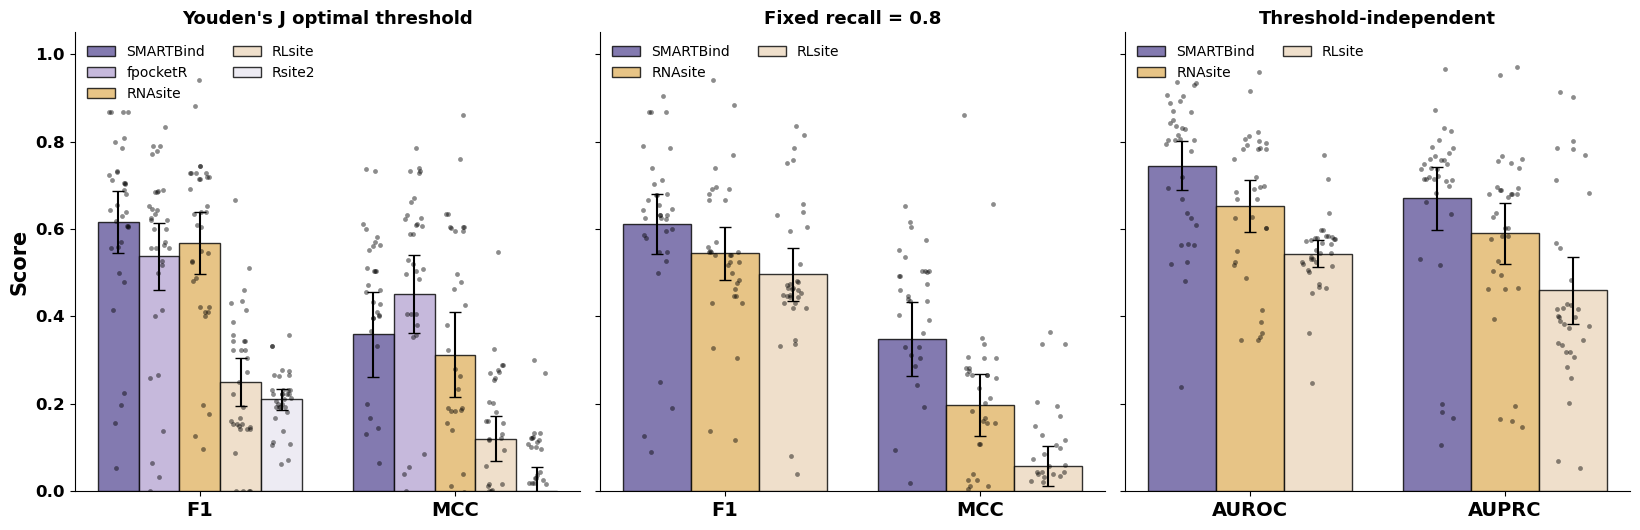

  SMARTBind F1     @ Youden_J_optimal       0.616 ± 0.204 (s.d.)
  SMARTBind MCC    @ Youden_J_optimal       0.360 ± 0.279 (s.d.)
  SMARTBind F1     @ fixed_recall_0.8       0.612 ± 0.194 (s.d.)
  SMARTBind MCC    @ fixed_recall_0.8       0.348 ± 0.242 (s.d.)
  SMARTBind AUROC  @ threshold_independent  0.745 ± 0.162 (s.d.)
  SMARTBind AUPRC  @ threshold_independent  0.670 ± 0.205 (s.d.)


In [2]:
# ── Fig. 3a — three metric groups across the 34 time-dependent complexes ─────
GROUPS = [("Youden_J_optimal", ["F1", "MCC"], "Youden's J optimal threshold"),
          ("fixed_recall_0.8", ["F1", "MCC"], "Fixed recall = 0.8"),
          ("threshold_independent", ["AUROC", "AUPRC"], "Threshold-independent")]

fig, axes = plt.subplots(1, 3, figsize=(16.5, 5.4), sharey=True)
rng = np.random.default_rng(42)

for ax, (group, metrics, title) in zip(axes, GROUPS):
    block = fig3a[fig3a.metric_group == group]
    # each group is drawn for the models that actually have values in it
    models = [m for m in MODEL_COLORS if m in set(block.model)]
    width = 0.8 / len(models)
    x = np.arange(len(metrics), dtype=float)

    for j, model in enumerate(models):
        offset = width * (j - (len(models) - 1) / 2)
        for i, metric in enumerate(metrics):
            vals = block.loc[(block.model == model) & (block.metric == metric), "value"].values
            mean, ci = mean_ci95(vals)
            ax.bar(x[i] + offset, mean, width, yerr=ci, color=MODEL_COLORS[model], alpha=0.8,
                   capsize=4, edgecolor="black", linewidth=1, zorder=3,
                   label=model if i == 0 else None)
            jitter = rng.uniform(-width * 0.25, width * 0.25, vals.size)
            ax.scatter(np.full(vals.size, x[i] + offset) + jitter, vals,
                       color="black", s=12, alpha=0.45, zorder=10, linewidths=0)

    ax.set_xticks(x)
    ax.set_xticklabels(metrics, fontsize=14, fontweight="bold")
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_ylim(0, 1.05)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="y", labelsize=12)
    ax.legend(frameon=False, fontsize=10, ncol=2, loc="upper left")

axes[0].set_ylabel("Score", fontsize=15, fontweight="bold")
for label in axes[0].get_yticklabels():
    label.set_fontweight("bold")
plt.tight_layout()
plt.savefig(OUT / "Fig3a_benchmark_metrics.pdf", bbox_inches="tight", dpi=300)
plt.savefig(OUT / "Fig3a_benchmark_metrics.png", bbox_inches="tight", dpi=600)
plt.show()

for group, metrics, _ in GROUPS:
    for metric in metrics:
        row = fig3a_summary[(fig3a_summary.metric_group == group)
                            & (fig3a_summary.metric == metric)
                            & (fig3a_summary.model == "SMARTBind")].iloc[0]
        print(f"  SMARTBind {metric:<6} @ {group:<22} {row['mean']:.3f} ± {row['sd']:.3f} (s.d.)")

  radar draws 3 of 5 methods: ['SMARTBind', 'RNAsite', 'RLsite']
    excluded: Rsite2 — binary binding labels, no continuous score; excluded from the AUROC comparison
    excluded: fpocketR — binary binding labels, no continuous score; excluded from the AUROC comparison


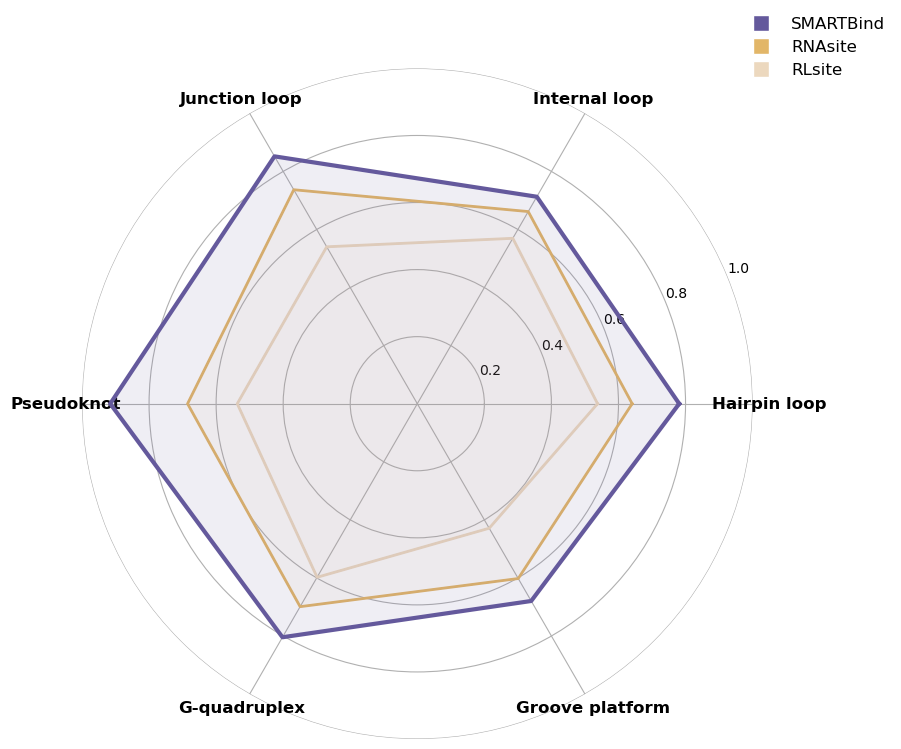

  motif                SMARTBind     RNAsite      RLsite   n cases
  Hairpin loop            0.7811      0.6408      0.5376        11
  Internal loop           0.7128      0.6617      0.5696        17
  Junction loop           0.8518      0.7369      0.5403        19
  Pseudoknot              0.9158      0.6852      0.5370         3
  G-quadruplex            0.8043      0.6990      0.5978         1
  Groove platform         0.6794      0.6021      0.4289         3


In [3]:
# ── Fig. 3b — mean AUROC per RNA 3D motif category (radar) ───────────────────
CATEGORIES = ["Hairpin loop", "Internal loop", "Junction loop",
              "Pseudoknot", "G-quadruplex", "Groove platform"]

# The Source Data carries all five binding-site methods, but the radar draws only the
# three with continuous scores; `plotted_in_panel` marks which, so the subset comes out
# of the table rather than a list here that could drift from it.
RADAR_MODELS = [m for m in MODEL_COLORS
                if m in set(fig3b.loc[fig3b.plotted_in_panel == 1, "model"])]
excluded = fig3b.loc[fig3b.plotted_in_panel == 0, ["model", "excluded_reason"]].drop_duplicates()
print(f"  radar draws {len(RADAR_MODELS)} of {fig3b.model.nunique()} methods: {RADAR_MODELS}")
for _, r in excluded.iterrows():
    print(f"    excluded: {r.model} ({r.excluded_reason})")

vertex = {m: [fig3b.loc[(fig3b.model == m) & (fig3b.motif_category == c), "auroc"].mean()
              for c in CATEGORIES] for m in RADAR_MODELS}

angles = np.linspace(0, 2 * np.pi, len(CATEGORIES), endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(9, 7.5), subplot_kw=dict(polar=True))
for model in RADAR_MODELS:
    vals = vertex[model] + vertex[model][:1]
    lead = model == "SMARTBind"
    ax.plot(angles, vals, linewidth=3 if lead else 2, color=MODEL_COLORS[model],
            zorder=5 if lead else 3)
    ax.fill(angles, vals, color=MODEL_COLORS[model], alpha=0.10 if lead else 0.05,
            zorder=5 if lead else 3)

ax.set_xticks(angles[:-1])
ax.set_xticklabels([])
for angle, name in zip(angles[:-1], CATEGORIES):
    ax.text(angle, 1.05, name, ha="center", va="center", fontsize=12, fontweight="bold")
ax.set_ylim(0, 1.0)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(["0.2", "0.4", "0.6", "0.8", "1.0"], fontsize=10)
ax.spines["polar"].set_visible(False)
ax.legend(handles=[Line2D([0], [0], marker="s", color="w", markerfacecolor=MODEL_COLORS[m],
                          markersize=12, label=m) for m in RADAR_MODELS],
          loc="upper right", bbox_to_anchor=(1.22, 1.10), frameon=False, fontsize=12)

plt.tight_layout()
plt.savefig(OUT / "Fig3b_motif_radar.pdf", bbox_inches="tight", dpi=300)
plt.savefig(OUT / "Fig3b_motif_radar.png", bbox_inches="tight", dpi=600)
plt.show()

print(f"  {'motif':<18}" + "".join(f"{m:>12}" for m in RADAR_MODELS) + f"{'n cases':>10}")
for i, c in enumerate(CATEGORIES):
    n = fig3b.loc[(fig3b.model == "SMARTBind") & (fig3b.motif_category == c)].shape[0]
    print(f"  {c:<18}" + "".join(f"{vertex[m][i]:>12.4f}" for m in RADAR_MODELS) + f"{n:>10}")

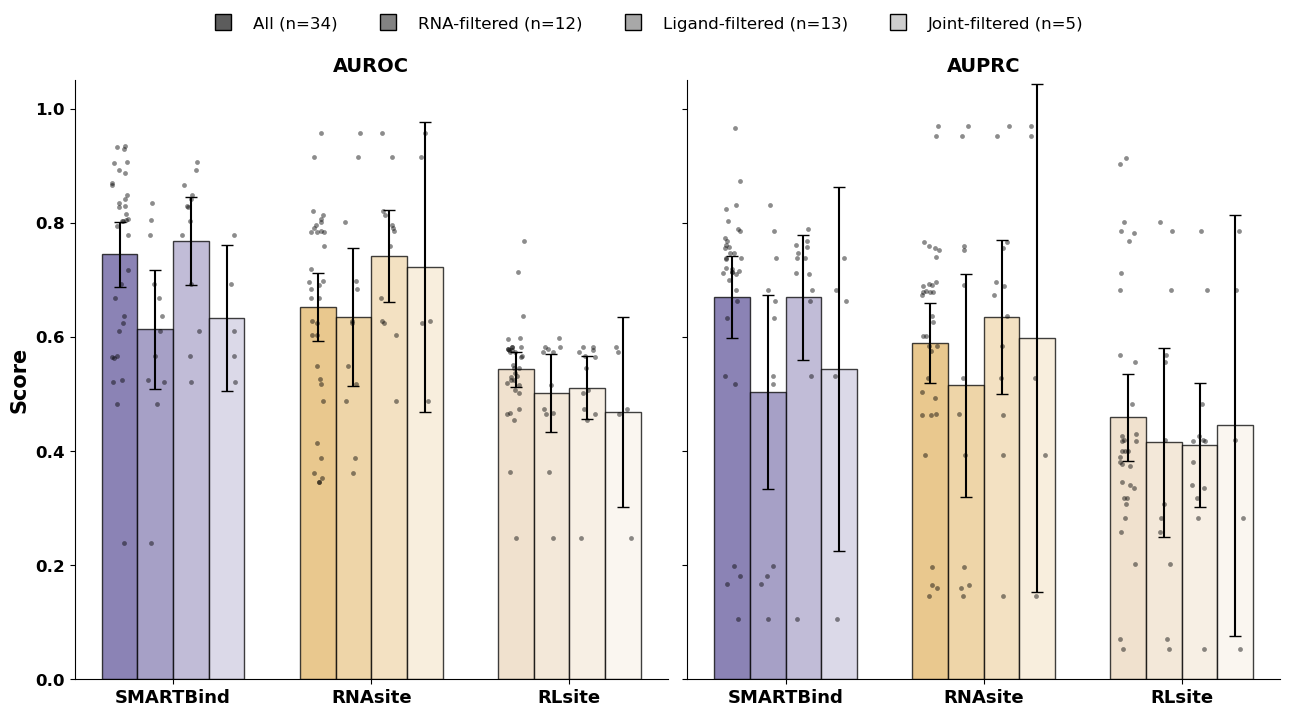

  SMARTBind AUROC  All (n=34)               0.745 ± 0.057 (95% CI)
  SMARTBind AUROC  RNA-filtered (n=12)      0.613 ± 0.105 (95% CI)
  SMARTBind AUROC  Ligand-filtered (n=13)   0.768 ± 0.078 (95% CI)
  SMARTBind AUROC  Joint-filtered (n=5)     0.634 ± 0.128 (95% CI)


In [4]:
# ── Fig. 3c / 3d — performance stratified by data-leakage filter ─────────────
# The bar for each (model, subset) is the mean over that subset's complexes, with a
# 95% t-interval; the dots are the individual complexes.  Subset membership comes
# from the `filter_scheme` column of the tables.
def filter_panel(table, metrics, models, ylabel, out_stem, figsize=(13, 6.8)):
    grads = {m: gradient(MODEL_COLORS[m], len(SPLITS)) for m in models}
    fig, axes = plt.subplots(1, len(metrics), figsize=figsize, sharey=True, squeeze=False)
    axes = axes[0]
    width, x = 0.18, np.arange(len(models), dtype=float)
    rng = np.random.default_rng(42)

    for ax, metric in zip(axes, metrics):
        for i, split in enumerate(SPLITS):
            offset = width * (i - (len(SPLITS) - 1) / 2)
            for j, model in enumerate(models):
                vals = table.loc[(table.filter_scheme == split) & (table.model == model)
                                 & (table.metric == metric), "value"].values
                mean, ci = mean_ci95(vals)
                ax.bar(x[j] + offset, mean, width, yerr=ci, color=grads[model][i], alpha=0.75,
                       capsize=4, edgecolor="black", linewidth=1)
                jitter = rng.uniform(-width * 0.25, width * 0.25, vals.size)
                ax.scatter(np.full(vals.size, x[j] + offset) + jitter, vals,
                           color="black", s=12, alpha=0.45, zorder=10, linewidths=0)
        ax.set_xticks(x)
        ax.set_xticklabels(models, fontsize=13, fontweight="bold")
        ax.set_title(metric, fontsize=14, fontweight="bold")
        ax.set_ylim(0, 1.05)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.tick_params(axis="y", labelsize=12)

    axes[0].set_ylabel(ylabel, fontsize=15, fontweight="bold")
    for label in axes[0].get_yticklabels():
        label.set_fontweight("bold")
    # one legend for the subsets, labelled with the n the data actually carries
    grey = gradient("#5C5C5C", len(SPLITS))
    fig.legend(handles=[Line2D([0], [0], marker="s", color="w", markerfacecolor=grey[i],
                               markeredgecolor="black", markersize=12, label=legend_for[s])
                        for i, s in enumerate(SPLITS)],
               loc="upper center", bbox_to_anchor=(0.5, 1.06), ncol=len(SPLITS),
               frameon=False, fontsize=12)
    plt.tight_layout()
    plt.savefig(OUT / f"{out_stem}.pdf", bbox_inches="tight", dpi=300)
    plt.savefig(OUT / f"{out_stem}.png", bbox_inches="tight", dpi=600)
    plt.show()


filter_panel(fig3c, ["AUROC", "AUPRC"], ["SMARTBind", "RNAsite", "RLsite"],
             "Score", "Fig3c_auroc_auprc_by_filter")
for split in SPLITS:
    r = fig3c_summary[(fig3c_summary.filter_scheme == split) & (fig3c_summary.metric == "AUROC")
                      & (fig3c_summary.model == "SMARTBind")].iloc[0]
    print(f"  SMARTBind AUROC  {legend_for[split]:<24} {r['mean']:.3f} ± {r['ci95_half_width']:.3f} (95% CI)")

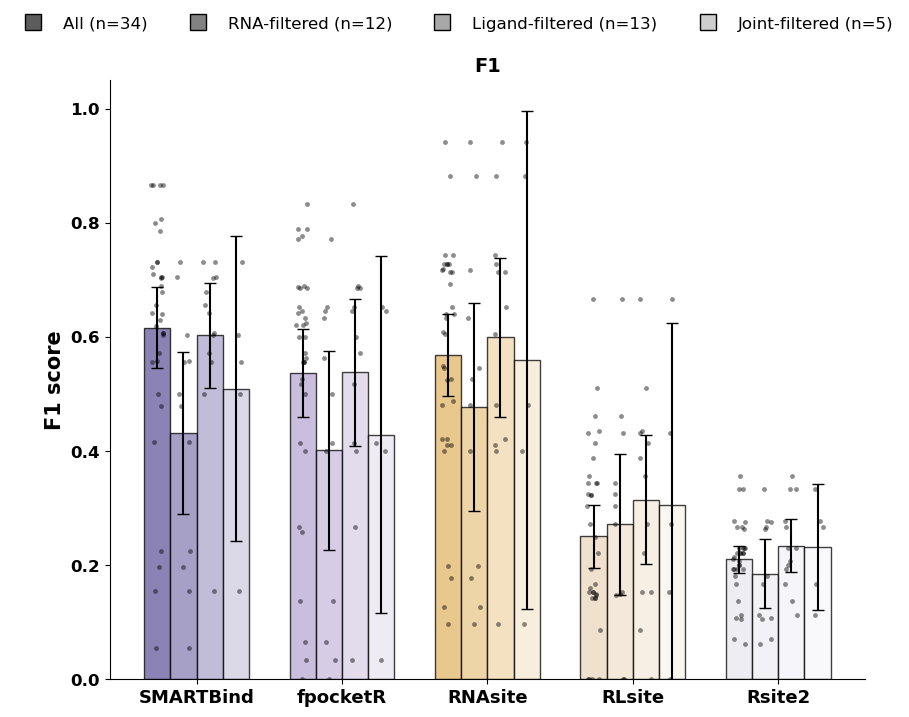

  SMARTBind F1     All (n=34)               0.616 ± 0.071 (95% CI)
  SMARTBind F1     RNA-filtered (n=12)      0.432 ± 0.142 (95% CI)
  SMARTBind F1     Ligand-filtered (n=13)   0.603 ± 0.092 (95% CI)
  SMARTBind F1     Joint-filtered (n=5)     0.509 ± 0.268 (95% CI)


In [5]:
# ── Fig. 3d — F1 at the Youden's J threshold, same four subsets ──────────────
filter_panel(fig3d, ["F1"], ["SMARTBind", "fpocketR", "RNAsite", "RLsite", "Rsite2"],
             "F1 score", "Fig3d_f1_by_filter", figsize=(8.5, 6.8))
for split in SPLITS:
    r = fig3d_summary[(fig3d_summary.filter_scheme == split)
                      & (fig3d_summary.model == "SMARTBind")].iloc[0]
    print(f"  SMARTBind F1     {legend_for[split]:<24} {r['mean']:.3f} ± {r['ci95_half_width']:.3f} (95% CI)")

In [6]:
# ── Self-check: every plotted value recomputed from the per-case tables ──────
failures = []


def compare(label, got, want, tol=5e-4):
    if abs(float(got) - float(want)) > tol:
        failures.append(f"{label}: recomputed {float(got):.6f} vs shipped {float(want):.6f}")
        return False
    return True


checks = 0
print("Fig. 3a")
for _, row in fig3a_summary.iterrows():
    v = fig3a.loc[(fig3a.metric_group == row.metric_group) & (fig3a.metric == row.metric)
                  & (fig3a.model == row.model), "value"].values
    mean, ci = mean_ci95(v)
    ok = all([compare(f"3a {row.model} {row.metric} n", len(v), row.n_targets, 0),
              compare(f"3a {row.model} {row.metric} mean", mean, row["mean"]),
              compare(f"3a {row.model} {row.metric} sd", v.std(ddof=1), row["sd"]),
              compare(f"3a {row.model} {row.metric} ci95", ci, row.ci95_half_width)])
    checks += 4
print(f"  {len(fig3a_summary)} bars   {'ok' if not failures else 'MISMATCH'}")

print("\nFig. 3b")
drawn = set(fig3b_summary.loc[fig3b_summary.plotted_in_panel == 1, "model"])
if drawn != set(RADAR_MODELS):
    failures.append(f"3b: summary marks {sorted(drawn)} plotted, radar drew {RADAR_MODELS}")
print(f"  plotted_in_panel agrees between the per-case and summary tables: "
      f"{drawn == set(fig3b.loc[fig3b.plotted_in_panel == 1, 'model'])}")
for _, row in fig3b_summary.iterrows():
    v = fig3b.loc[(fig3b.model == row.model)
                  & (fig3b.motif_category == row.motif_category), "auroc"].values
    ok = all([compare(f"3b {row.model} {row.motif_category} n", len(v), row.n_cases, 0),
              compare(f"3b {row.model} {row.motif_category} mean", v.mean(),
                      row.mean_auroc_radar_vertex)])
    checks += 2
print(f"  {len(fig3b_summary)} radar vertices   {'ok' if not failures else 'MISMATCH'}")

print("\nFig. 3c / 3d: subset sizes and bar heights")
for tag, table, summary in (("3c", fig3c, fig3c_summary), ("3d", fig3d, fig3d_summary)):
    for _, row in summary.iterrows():
        v = table.loc[(table.filter_scheme == row.filter_scheme) & (table.model == row.model)
                      & (table.metric == row.metric), "value"].values
        mean, ci = mean_ci95(v)
        compare(f"{tag} {row.filter_scheme}/{row.model}/{row.metric} n", len(v), row.n_targets, 0)
        compare(f"{tag} {row.filter_scheme}/{row.model}/{row.metric} mean", mean, row["mean"])
        compare(f"{tag} {row.filter_scheme}/{row.model}/{row.metric} ci95", ci, row.ci95_half_width)
        checks += 3
    sizes = {s: summary.loc[summary.filter_scheme == s, "n_targets"].unique().tolist()
             for s in SPLITS}
    print(f"  Fig {tag} subset sizes: " + "  ".join(f"{s}={sizes[s]}" for s in SPLITS))

expected = {"All": 34, "RNA-filtered": 12, "Ligand-filtered": 13, "Joint-filtered": 5}
for split, n in expected.items():
    got = int(fig3c_summary.loc[fig3c_summary.filter_scheme == split, "n_targets"].iloc[0])
    if got != n:
        failures.append(f"subset {split}: {got} complexes, expected {n}")
    print(f"  {legend_for[split]:<24} {'ok' if got == n else f'MISMATCH ({got})'}")

print()
if failures:
    for f in failures:
        print("  " + f)
    raise AssertionError(f"{len(failures)} value(s) do not reproduce the shipped summary")
print(f"PASS: every plotted value reproduces the shipped summary tables ({checks} checks)")

Fig. 3a
  22 bars   ok

Fig. 3b
  plotted_in_panel agrees between the per-case and summary tables: True
  30 radar vertices   ok

Fig. 3c / 3d — subset sizes and bar heights
  Fig 3c subset sizes: All=[34]  RNA-filtered=[12]  Ligand-filtered=[13]  Joint-filtered=[5]
  Fig 3d subset sizes: All=[34]  RNA-filtered=[12]  Ligand-filtered=[13]  Joint-filtered=[5]
  All (n=34)               ok
  RNA-filtered (n=12)      ok
  Ligand-filtered (n=13)   ok
  Joint-filtered (n=5)     ok

PASS — every plotted value reproduces the shipped summary tables (280 checks)
